$$
\begin{array}{c}
{\Huge \text{CAUSAL INFERENCE LAB 7}}\\
{\Large \textbf{Abhishek Bakshi}} \\
{\large \textit{Center for Data Science, New York University}} \\\\
{\Large \text{Office Hours: Wednesdays, 12:30 - 1:30 pm}} \\
{\Large \textit{Room 242, 60 5th Ave, 2nd floor}} \\\\
\text{Materials prepared by: Abhishek Bakshi, Xiang Gao}
\end{array}
$$

---

<h1 style="font-size: 42px;">Natural Experiments and Regression</h1>

---

<h1 style="font-size: 30px;">Today's Goals:</h1>

<ol style="font-size: 20px; line-height: 1.6;">
  <li>Natural Experiments, target population and treatment</li>
  <li>Balance tests for cluster randomization</li>
  <li>Descriptive regression vs causal regression</li>
  <li>Fair vs rigged randomization</li>
  <li>Standard errors for cluster randomization</li>
</ol>
---

<style>
body,
.jp-RenderedHTMLCommon,
.jp-RenderedMarkdown,
.markdown-body,
.vscode-body {
  font-family: Arial, Helvetica, sans-serif !important;
}
p, li, blockquote, td, th {
  font-size: 20px !important;
  line-height: 1.6 !important;
}
h1 {
  font-family: Arial, Helvetica, sans-serif !important;
  font-size: 42px !important;
  line-height: 1.25 !important;
  margin-top: 0.6em !important;
}
h2 {
  font-family: Arial, Helvetica, sans-serif !important;
  font-size: 30px !important;
  line-height: 1.3 !important;
  margin-top: 0.7em !important;
  border-bottom: 2px solid #4b4bb7;
  padding-bottom: 0.15em;
}
h3 {
  font-family: Arial, Helvetica, sans-serif !important;
  font-size: 25px !important;
  line-height: 1.35 !important;
  margin-top: 0.7em !important;
}
table { font-size: 19px !important; line-height: 1.45 !important; }
code, pre { font-size: 17px !important; }
blockquote { border-left: 5px solid #4b4bb7 !important; padding: 0.3em 0.8em !important; }
.MathJax, mjx-container { font-size: 115% !important; }
</style>

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

pd.set_option("display.precision", 3)
plt.rcParams.update({
    "font.size": 15, "axes.titlesize": 19, "axes.labelsize": 16,
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
})
SEED = 112
# Every cell that draws random numbers makes its own generator from SEED,
# so re-running a cell gives the same numbers.
print("Ready: natural experiments and regression.")

Ready: natural experiments and regression.


## 1. Natural experiments

---

With observational data we cannot randomize, so we try to recover the experimental assumption

$$
S \perp U
$$

in one of two ways:

1. **Mimic the reason** for $S \perp U$, randomization: find treatment that was assigned *as-if randomly* by some process in the world. This is a **natural experiment**.
2. **Mimic the consequence** of $S \perp U$, comparable groups: argue that treated and control units look alike apart from $S$.

A natural experiment is analysed exactly like an experiment. The hard part is the context: *why* was treatment (essentially) random?

### The Dutch Postcode Lottery

Kuhn et al. (2011) study the Dutch Postcode Lottery. People pay to play; a postcode (a very small neighbourhood) is drawn, and **every player in that postcode** wins €12,500. The question: how does a sudden increase in wealth change spending?

Let $Y$ be monthly discretionary spending after the draw, and $U$ all other influences on spending.

### Question 1: which population, which treatment?

1. Is winning the lottery as-if random among *all* Dutch residents?
2. For which population is winning plausibly as-if random?
3. A winner's neighbours might spend more too. Which assumption does that threaten if the treatment is *"I won"*?
4. The authors instead use $S_G = 1$ if a player lives in a winning postcode. Why does this help, and what does the effect of $S_G$ now include?

### What must hold for the simple comparison to be causal

With the treatment defined as $S_G$:

1. **As-if random assignment:** among players, winning postcodes are drawn independently of everything else, so $S_G \perp U$.
2. **SUTVA across postcodes:** no spillovers *between* postcodes. Spillovers between neighbours *within* a postcode are now part of the treatment.
3. **Perfect compliance with the lottery:** winners take their prize. If not, the comparison is an intention-to-treat effect.

Then the identification argument is the one from experiments:

$$
\mathbb E[Y(S_G=1,U)-Y(S_G=0,U)] = \mathbb E[Y\mid S_G=1]-\mathbb E[Y\mid S_G=0].
$$

This is the effect of living in a winning postcode **among players**, own prize plus neighbour spillovers. It is not the effect of €12,500 on a person whose neighbours did not win.

## 2. A simulated lottery

---

The function below builds a population of lottery players in 80 postcodes. Every household gets **both** potential outcomes, `y0` $=Y(S_G=0,U)$ and `y1` $=Y(S_G=1,U)$, plus a few columns researchers wouldn't observe.

One rule sets every household's monthly spending, in every year:

> **spending = `usual` level + local conditions that year + the household's own surprise that year**

- `usual` = €800 + €150 per household member + €300 for a big spender. It is the same in both years, so it is what carries over from last year to this year.
- This year has two extras: connected postcodes get €300 of favours from the officials, and living in a winning postcode adds €150 (€120 from the household's own prize, €30 from winning neighbours).
- To keep the rule short, age, employment and years of play are in the data but affect nothing.

The diagram shows every column that `make_world` and `run_lottery` create, and what causes what.

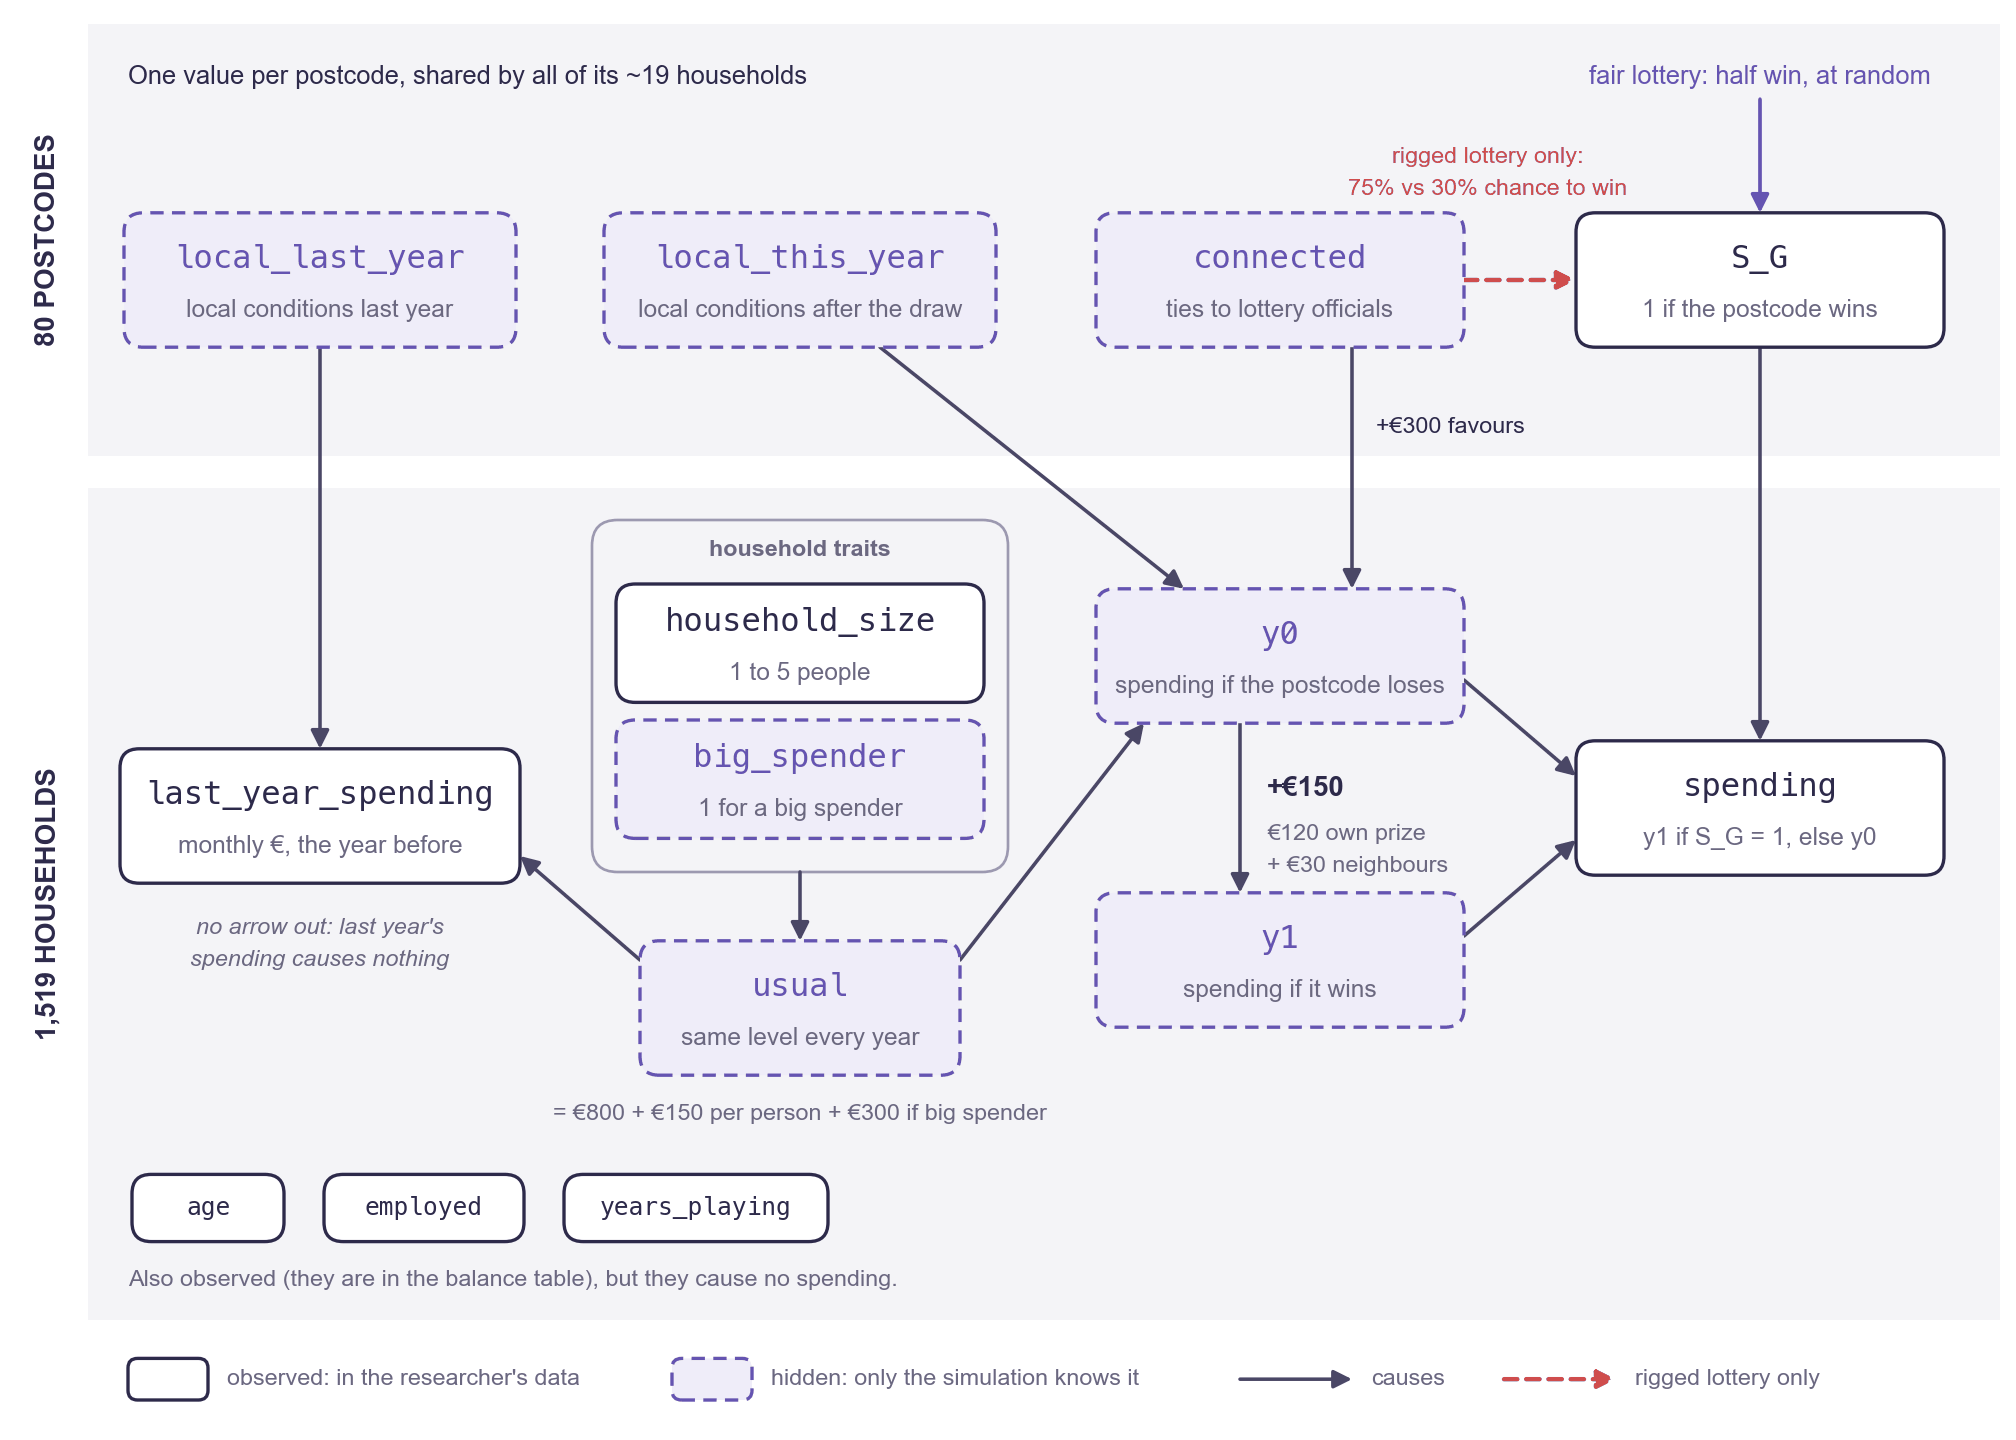

In [20]:
def make_world(n_postcodes, rng):
    """Lottery players nested in postcodes, with BOTH potential outcomes."""
    households = rng.integers(14, 25, size=n_postcodes)   # 14 to 24 households per postcode
    postcode = np.repeat(np.arange(n_postcodes), households)
    n = len(postcode)

    # Postcode level: one value per postcode, all UNOBSERVED
    connected = rng.binomial(1, 0.25, n_postcodes)       # ties to lottery officials
    local_last_year = rng.normal(0, 150, n_postcodes)    # a good or bad year for the area (€)
    local_this_year = rng.normal(0, 150, n_postcodes)

    # Household level
    household_size = rng.integers(1, 6, n)               # 1 to 5 people
    big_spender = rng.binomial(1, 0.3, n)                # UNOBSERVED: 1 for a big spender
    age = rng.integers(20, 81, n)                        # observed, but no effect on spending
    employed = rng.binomial(1, 0.7, n)                   # observed, but no effect on spending
    years_playing = rng.integers(0, 16, n)               # observed, but no effect on spending

    # Monthly spending (€) every year = usual level + local conditions + the household's own surprise
    usual = 800 + 150 * household_size + 300 * big_spender
    last_year_spending = usual + local_last_year[postcode] + rng.normal(0, 200, n)

    # This year, if the postcode loses (y0) and if it wins (y1).
    # last_year_spending is not in y0: what carries over is `usual`, not last year's surprise.
    # Connected postcodes also get favours from the officials this year (+€300), whoever wins.
    y0 = usual + local_this_year[postcode] + rng.normal(0, 200, n) + 300 * connected[postcode]
    y1 = y0 + 120 + 30   # €120 from the household's own prize + €30 from winning neighbours

    return pd.DataFrame({
        "postcode": postcode, "household_size": household_size, "age": age,
        "employed": employed, "years_playing": years_playing,
        "last_year_spending": last_year_spending,
        # columns no researcher would ever see:
        "big_spender": big_spender, "usual": usual, "connected": connected[postcode],
        "local_last_year": local_last_year[postcode], "local_this_year": local_this_year[postcode],
        "y0": y0, "y1": y1,
    })


HIDDEN = ["big_spender", "usual", "connected", "local_last_year", "local_this_year", "y0", "y1"]

world = make_world(80, np.random.default_rng(SEED))
true_effect = (world.y1 - world.y0).mean()

print(f"{len(world):,} lottery players in {world.postcode.nunique()} postcodes")
print(f"True effect of a winning postcode, E[Y(S_G=1,U) - Y(S_G=0,U)] = €{true_effect:.0f}")

1,519 lottery players in 80 postcodes
True effect of a winning postcode, E[Y(S_G=1,U) - Y(S_G=0,U)] = €150


Now run a **fair** draw: half of the postcodes win, chosen completely at random. A researcher only gets `observed`, the data without the hidden columns.

In [22]:
def run_lottery(world, rule, rng):
    """Draw winning postcodes and return what a researcher would observe."""
    n_postcodes = world.postcode.nunique()
    if rule == "fair":
        # Half of all postcodes win, chosen completely at random
        wins = rng.permutation(np.r_[np.ones(n_postcodes // 2), np.zeros(n_postcodes - n_postcodes // 2)])
    elif rule == "rigged":
        # Officials tilt the draw toward connected postcodes
        p_win = np.where(world.groupby("postcode").connected.first() == 1, 0.75, 0.30)
        wins = rng.binomial(1, p_win)
    data = world.copy()
    data["S_G"] = wins[data.postcode].astype(int)
    data["spending"] = np.where(data.S_G == 1, data.y1, data.y0)  # only one outcome is ever seen
    return data


fair = run_lottery(world, "fair", np.random.default_rng(SEED + 1))
observed = fair.drop(columns=HIDDEN)
print(f"Winning postcodes: {fair.groupby('postcode').S_G.first().sum()} of {fair.postcode.nunique()}")
observed.sample(5)

Winning postcodes: 40 of 80


,postcode,household_size,age,employed,years_playing,last_year_spending,S_G,spending
1254,65,4,25,0,13,1321.117,0,1887.564
1272,66,1,80,1,1,1147.342,0,885.491
961,49,1,21,0,2,1174.332,1,1463.916
540,27,4,58,1,10,1829.743,0,1767.327
1080,56,4,54,1,12,1076.743,1,1926.123


### Balance tests

If $S_G \perp U$, pre-lottery variables should have the same mean in winning and losing postcodes. Prizes are assigned **by postcode**, so each comparison is a regression of the variable on $S_G$ with standard errors clustered by postcode. Section 6 shows why the clustering matters.

### Question 2: predict before running

We test 5 pre-lottery variables after a fair draw.

1. How many of them do you expect to have $p < 0.05$?
2. Would a single star make you doubt the lottery?
3. Why is `spending` (after the draw) not in the table?

In [4]:
BALANCE_VARIABLES = ["household_size", "age", "employed", "years_playing", "last_year_spending"]


def balance_table(data):
    """Regress each pre-lottery variable on S_G, clustering by postcode."""
    rows = []
    for variable in BALANCE_VARIABLES:
        fit = smf.ols(f"{variable} ~ S_G", data=data).fit(
            cov_type="cluster", cov_kwds={"groups": data.postcode})
        rows.append({
            "Pre-lottery variable": variable,
            "Losing postcodes": fit.params["Intercept"],
            "Winning postcodes": fit.params["Intercept"] + fit.params["S_G"],
            "Difference": fit.params["S_G"],
            "Clustered p-value": fit.pvalues["S_G"],
            "": "*" if fit.pvalues["S_G"] < 0.05 else "",
        })
    return pd.DataFrame(rows)


balance_fair = balance_table(fair)
display(balance_fair.style.format({
    "Losing postcodes": "{:,.2f}", "Winning postcodes": "{:,.2f}",
    "Difference": "{:,.2f}", "Clustered p-value": "{:.3f}",
}).hide(axis="index"))
print(f"Significant at 5%: {(balance_fair['Clustered p-value'] < 0.05).sum()} of {len(balance_fair)}")

Pre-lottery variable,Losing postcodes,Winning postcodes,Difference,Clustered p-value,
household_size,3.00,2.96,-0.03,0.593,
age,48.98,50.76,1.79,0.033,*
employed,0.67,0.69,0.01,0.569,
years_playing,7.60,7.57,-0.03,0.912,
last_year_spending,"1,340.36","1,298.78",-41.58,0.201,


Significant at 5%: 1 of 5


One star in five is no cause for concern: when every null hypothesis is true, 5% of tests reject at the 5% level **by construction**. Kuhn et al.'s balance table also has a couple of starred rows.

Let's check that claim by running the fair lottery 1,000 times and looking at the balance p-values for last year's spending. On the left, a household-level t-test that treats every household as an independent draw; on the right, the clustered regression.

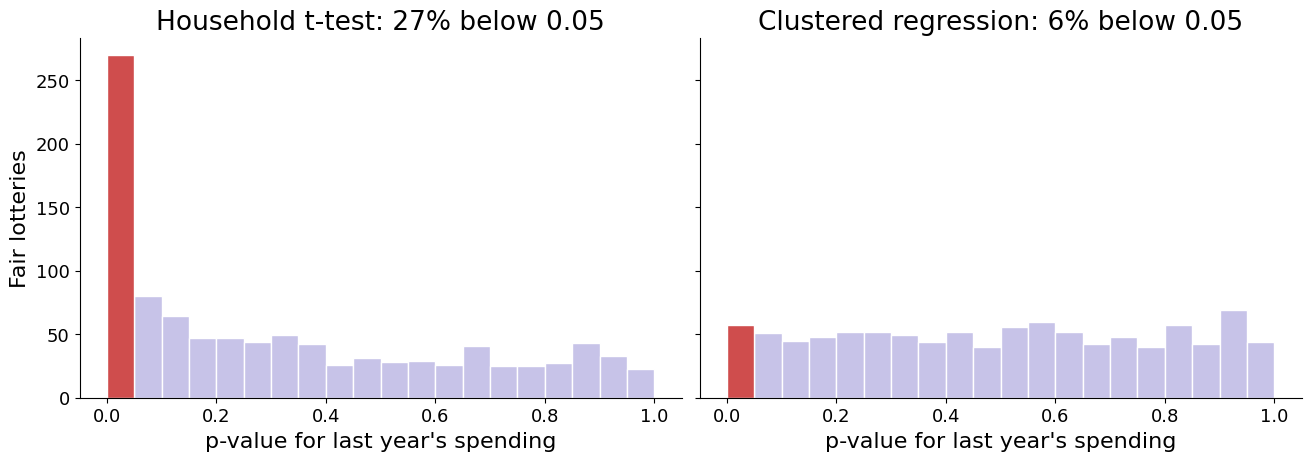

In [5]:
sim_rng = np.random.default_rng(SEED + 2)
naive_p, cluster_p = [], []
for _ in range(1000):
    d = run_lottery(world, "fair", sim_rng)
    winners, losers = d.last_year_spending[d.S_G == 1], d.last_year_spending[d.S_G == 0]
    naive_p.append(stats.ttest_ind(winners, losers, equal_var=False).pvalue)
    fit = smf.ols("last_year_spending ~ S_G", data=d).fit(
        cov_type="cluster", cov_kwds={"groups": d.postcode})
    cluster_p.append(fit.pvalues["S_G"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, p, name in [(axes[0], np.array(naive_p), "Household t-test"),
                    (axes[1], np.array(cluster_p), "Clustered regression")]:
    ax.hist(p, bins=20, range=(0, 1), color="#C7C3E8", edgecolor="white")
    ax.hist(p[p < 0.05], bins=1, range=(0, 0.05), color="#CF4D4D", edgecolor="white")
    ax.set(title=f"{name}: {np.mean(p < 0.05):.0%} below 0.05", xlabel="p-value for last year's spending")
axes[0].set(ylabel="Fair lotteries")
plt.show()

Under a fair lottery the clustered p-values are flat and about 5% fall below 0.05. The household t-test flags "imbalance" far too often: it treats the ~19 neighbours in a postcode as 19 independent draws, when the lottery made only one.

## 3. Regression as a descriptive tool

---

The descriptive regression

$$
Y = \beta_0 + \beta_1 X + \varepsilon
$$

is the **best linear predictor** of $Y$ given $X$: $(\beta_0,\beta_1)$ minimise $\mathbb E[(Y-(b_0+b_1X))^2]$. It exists for any jointly distributed $X$ and $Y$ with $\operatorname{Var}(X)>0$, just like a correlation (crime and ice-cream sales). The residual $\varepsilon \equiv Y-(\beta_0+\beta_1X)$ is only the prediction error; it has no meaning of its own.

### Question 3: a positive slope with no effect

We regress spending after the draw on spending the year before. **In our simulated world, last year's spending has no causal effect on this year's** (look at the formula for `y0`: `last_year_spending` is not in it; in the diagram, no arrow leaves it). What carries over is the household's `usual` level, not last year's surprise.

1. Predict the sign of the slope.
2. Use the diagram: which column causes both `last_year_spending` and `y0`, and what is it made of? Which parts are hidden?

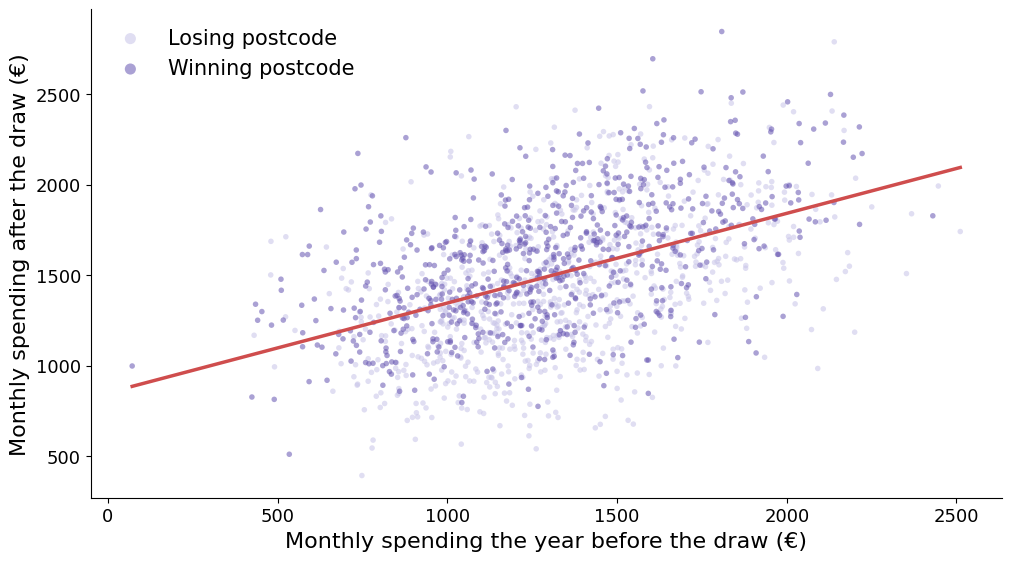

Best linear predictor: spending = 850 + 0.50 × last year's spending
Causal effect of last year's spending in this simulated world: 0.00


In [6]:
descriptive = smf.ols("spending ~ last_year_spending", data=observed).fit()
b0, b1 = descriptive.params

fig, ax = plt.subplots(figsize=(10, 5.5))
for s, color, label in [(0, "#C7C3E8", "Losing postcode"), (1, "#6554B1", "Winning postcode")]:
    group = observed[observed.S_G == s]
    ax.scatter(group.last_year_spending, group.spending, s=16, alpha=0.55,
               color=color, edgecolor="none", label=label)
grid = np.linspace(observed.last_year_spending.min(), observed.last_year_spending.max(), 200)
ax.plot(grid, b0 + b1 * grid, color="#CF4D4D", lw=2.5)
ax.set(xlabel="Monthly spending the year before the draw (€)", ylabel="Monthly spending after the draw (€)")
ax.legend(loc="upper left", markerscale=2)
plt.show()

print(f"Best linear predictor: spending = {b0:.0f} + {b1:.2f} × last year's spending")
print("Causal effect of last year's spending in this simulated world: 0.00")

### The slope by hand

The descriptive slope is identified as $\beta_1 = \operatorname{Cov}(X,Y)/\operatorname{Var}(X)$, and OLS uses the sample versions.

In [7]:
x = observed.last_year_spending
y = observed.spending
beta1_by_hand = np.cov(x, y)[0, 1] / np.var(x, ddof=1)
print(f"By hand: {beta1_by_hand:.4f};  statsmodels: {descriptive.params['last_year_spending']:.4f}")

By hand: 0.4953;  statsmodels: 0.4953


### Residuals are zero on average by construction

The first-order conditions of the minimisation give

$$
\mathbb E[\varepsilon]=0, \qquad \mathbb E[X\varepsilon]=0
$$

for **every** descriptive regression. That is why descriptive parameters are always identified. Check it on our fitted line, and on a regression with no causal story at all.

In [8]:
e_hat = descriptive.resid
x = observed.last_year_spending
print(f"mean of residuals         = {e_hat.mean():.10f}")
print(f"mean of x × residuals     = {(x * e_hat).mean():.10f}")

# Same check for a regression with no causal story at all: spending on years of play
nonsense = smf.ols("spending ~ years_playing", data=observed).fit()
print(f"years_playing regression: {nonsense.resid.mean():.10f}, "
      f"{(observed.years_playing * nonsense.resid).mean():.10f}")

mean of residuals         = -0.0000000000
mean of x × residuals     = -0.0000000008
years_playing regression: 0.0000000000, 0.0000000000


Both are zero up to rounding, for any $X$. These are properties of the fitted line, not facts about the world, so they cannot tell us whether a slope is causal.

## 4. Regression with a binary treatment

---

The **causal** regression is a claim about how spending is generated:

$$
Y(S_G,U) = \alpha_0 + \alpha_1 S_G + U, \qquad \mathbb E[U]=0,
$$

where $U$ is all other causes of spending. Unlike $\varepsilon$, $U$ is defined by the world, so $\mathbb E[S_G U]=0$ is **not** automatic. It holds if $S_G \perp U$, and then

$$
\alpha_1=\frac{\operatorname{Cov}(S_G,Y)}{\operatorname{Var}(S_G)}
=\frac{p(1-p)\,(\mathbb E[Y\mid S_G=1]-\mathbb E[Y\mid S_G=0])}{p(1-p)}
=\mathbb E[Y\mid S_G=1]-\mathbb E[Y\mid S_G=0],
$$

with $p=P(S_G=1)$.

### Question 4: estimate it by hand

1. Before running anything: what will the OLS intercept be, and what will the slope be?
2. Write the covariance-over-variance estimate for $S_G$, and check that $\widehat{\operatorname{Var}}(S_G)\approx \hat p(1-\hat p)$.

In [9]:
# By hand: covariance over variance
S = observed.S_G
Y = observed.spending
alpha1_by_hand = np.cov(S, Y)[0, 1] / np.var(S, ddof=1)

p_hat = S.mean()
print(f"Var(S_G) = {np.var(S, ddof=1):.4f};  p(1 - p) = {p_hat * (1 - p_hat):.4f}  (equal up to n/(n-1))")
print(f"Cov/Var slope                  = {alpha1_by_hand:.2f}")
print(f"Winners' mean - losers' mean   = {Y[S == 1].mean() - Y[S == 0].mean():.2f}")

Var(S_G) = 0.2498;  p(1 - p) = 0.2496  (equal up to n/(n-1))
Cov/Var slope                  = 156.48
Winners' mean - losers' mean   = 156.48


Now the same thing with `statsmodels`, using robust (HC0) standard errors as in the lecture. Because this is a simulation, we can also print the truth.

In [10]:
robust = smf.ols("spending ~ S_G", data=observed).fit(cov_type="HC0")

print(f"OLS intercept = {robust.params['Intercept']:.2f}  (losers' mean = {Y[S == 0].mean():.2f})")
print(f"OLS slope     = {robust.params['S_G']:.2f}")
print(f"True effect   = {true_effect:.2f}")

OLS intercept = 1429.12  (losers' mean = 1429.12)
OLS slope     = 156.48
True effect   = 150.00


### Checking $\mathbb E[S_G U]=0$ with the hidden columns

In real data $U$ is unobservable. In our simulation it is not, the centred `y0`: every arrow into `y0` in the diagram is a piece of $U$. Since every household's effect is exactly €150, the OLS slope minus the truth equals the gap in average $U$ between winners and losers.

In [11]:
# U = all other causes of spending, centred so that E[U] = 0
U = fair.y0 - fair.y0.mean()
print(f"mean of S_G × U                      = {(fair.S_G * U).mean():7.2f}")
print(f"mean U, winners minus losers         = {U[fair.S_G == 1].mean() - U[fair.S_G == 0].mean():7.2f}")
print(f"OLS slope minus true effect          = {robust.params['S_G'] - true_effect:7.2f}")

mean of S_G × U                      =    1.62
mean U, winners minus losers         =    6.48
OLS slope minus true effect          =    6.48


A fair draw keeps $\mathbb E[S_G U]$ and the $U$-gap close to zero. Whatever gap remains is chance, and Section 6 measures how large chance gaps are.

## 5. A rigged lottery

---

Balance tests cannot check unobservables. The lecture's example: what if friends of the lottery commission were more likely to win, and also enjoyed other perks of having powerful friends?

Our world has exactly that: the hidden `connected` column. Connected postcodes get other favours in the year after the draw (+€300 in `y0`), whoever wins. Now the officials **rig** the draw: connected postcodes win with probability 0.75, all others with probability 0.30. In the diagram, the rigging is the red dashed arrow from `connected` to $S_G$.

### Question 5: predict before running

1. Will the balance table catch the rigging?
2. Will the OLS slope be too high or too low? Why?

In [12]:
rigged = run_lottery(world, "rigged", np.random.default_rng(SEED + 3))

balance_rigged = balance_table(rigged)
display(balance_rigged.style.format({
    "Losing postcodes": "{:,.2f}", "Winning postcodes": "{:,.2f}",
    "Difference": "{:,.2f}", "Clustered p-value": "{:.3f}",
}).hide(axis="index"))

rigged_fit = smf.ols("spending ~ S_G", data=rigged).fit(
    cov_type="cluster", cov_kwds={"groups": rigged.postcode})
U_rigged = rigged.y0 - rigged.y0.mean()
print(f"Rigged lottery: OLS slope = €{rigged_fit.params['S_G']:.0f} "
      f"(95% CI {rigged_fit.conf_int().loc['S_G', 0]:.0f} to {rigged_fit.conf_int().loc['S_G', 1]:.0f}); "
      f"true effect = €{true_effect:.0f}")
print(f"mean of S_G × U = {(rigged.S_G * U_rigged).mean():.2f}")
print("Share of winning postcodes that are connected:",
      f"{rigged.groupby('postcode').agg(S=('S_G', 'first'), c=('connected', 'first')).query('S == 1').c.mean():.0%}")

Pre-lottery variable,Losing postcodes,Winning postcodes,Difference,Clustered p-value,
household_size,2.99,2.96,-0.04,0.565,
age,50.25,49.20,-1.05,0.249,
employed,0.69,0.67,-0.02,0.453,
years_playing,7.41,7.86,0.46,0.127,
last_year_spending,"1,329.97","1,305.44",-24.53,0.467,


Rigged lottery: OLS slope = €261 (95% CI 169 to 353); true effect = €150
mean of S_G × U = 26.44
Share of winning postcodes that are connected: 47%


Every observed variable still looks balanced, yet $\mathbb E[S_G U]$ is far from zero and the confidence interval misses the truth. The data cannot rule this out; only the **institutional context** can. Kuhn et al. are persuaded the Dutch lottery is run honestly. We might be less willing to believe the same design in a setting with a lot of corruption.

## 6. Standard errors must respect the design

---

Back to the fair lottery. Robust (HC0) standard errors are valid for a large i.i.d. sample. Here, the ~19 households in a postcode share the same $S_G$ and the same local conditions this year (the top lane of the diagram), so they are not independent draws. **Clustered** standard errors allow arbitrary correlation within a postcode. They are valid when the clusters are independent and there are many of them, and we cluster at the level at which treatment is assigned.

### Question 6: predict before running

1. Will clustering change the estimated effect?
2. Which standard error will be larger?

In [13]:
clustered = smf.ols("spending ~ S_G", data=observed).fit(
    cov_type="cluster", cov_kwds={"groups": observed.postcode})

comparison = pd.DataFrame({
    "Estimate": [robust.params["S_G"], clustered.params["S_G"]],
    "Standard error": [robust.bse["S_G"], clustered.bse["S_G"]],
    "95% CI lower": [robust.conf_int().loc["S_G", 0], clustered.conf_int().loc["S_G", 0]],
    "95% CI upper": [robust.conf_int().loc["S_G", 1], clustered.conf_int().loc["S_G", 1]],
}, index=["Robust (HC0), households independent", "Clustered by postcode"])
display(comparison.style.format("{:.1f}"))
print(f"Households: {len(observed):,};  independently assigned postcodes: {observed.postcode.nunique()}")

,Estimate,Standard error,95% CI lower,95% CI upper
"Robust (HC0), households independent",156.5,19.1,119.0,194.0
Clustered by postcode,156.5,44.8,68.6,244.4


Households: 1,519;  independently assigned postcodes: 80


### Re-run the lottery 1,000 times

Which standard error is right? With real data we would never know. In a simulation we can keep the same households and postcodes, re-run only the fair draw 1,000 times, and measure how much the estimate really moves.

Spread of the estimate across 1,000 lotteries (true SD): 45.9
Average robust (HC0) SE:  19.1
Average clustered SE:     44.9


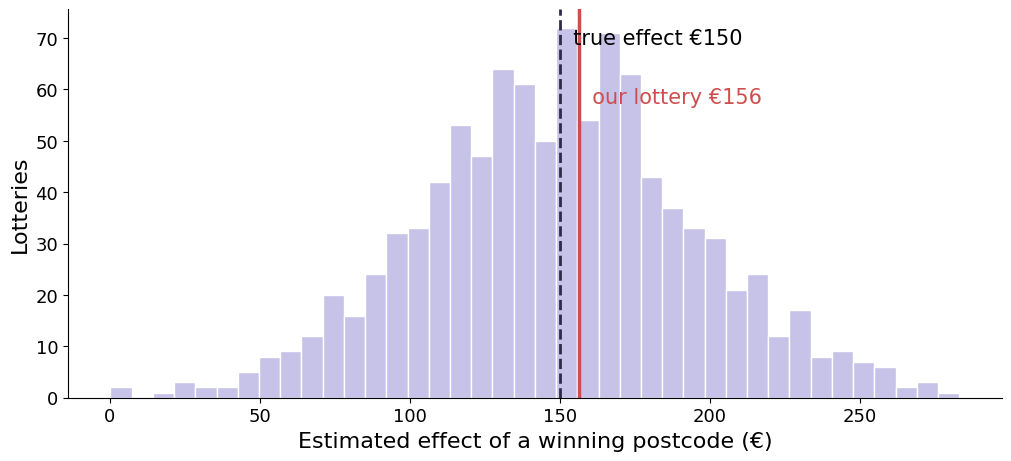

In [14]:
def rerun(world, n_reps, rng):
    """Same households, same postcodes: re-run only the fair draw, many times."""
    rows = []
    for _ in range(n_reps):
        d = run_lottery(world, "fair", rng)
        model = smf.ols("spending ~ S_G", data=d)
        hc0 = model.fit(cov_type="HC0")
        clu = model.fit(cov_type="cluster", cov_kwds={"groups": d.postcode})
        rows.append({"estimate": hc0.params["S_G"], "se_hc0": hc0.bse["S_G"], "se_cluster": clu.bse["S_G"]})
    return pd.DataFrame(rows)


reruns = rerun(world, 1000, np.random.default_rng(SEED + 4))
print(f"Spread of the estimate across 1,000 lotteries (true SD): {reruns.estimate.std():.1f}")
print(f"Average robust (HC0) SE:  {reruns.se_hc0.mean():.1f}")
print(f"Average clustered SE:     {reruns.se_cluster.mean():.1f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(reruns.estimate, bins=40, color="#C7C3E8", edgecolor="white")
ax.axvline(true_effect, color="#2D2A4A", ls="--", lw=2)
ax.axvline(robust.params["S_G"], color="#CF4D4D", lw=2.5)
ax.text(true_effect, ax.get_ylim()[1] * 0.95, f"  true effect €{true_effect:.0f}", va="top")
ax.text(robust.params["S_G"], ax.get_ylim()[1] * 0.80, f"  our lottery €{robust.params['S_G']:.0f}",
        va="top", color="#CF4D4D")
ax.set(xlabel="Estimated effect of a winning postcode (€)", ylabel="Lotteries")
plt.show()

A 95% confidence interval should cover the truth in about 95% of repeated lotteries, the same idea as the repeated-sampling plot from Lab 4. Here are the first 100 intervals of each kind (red = misses the truth).

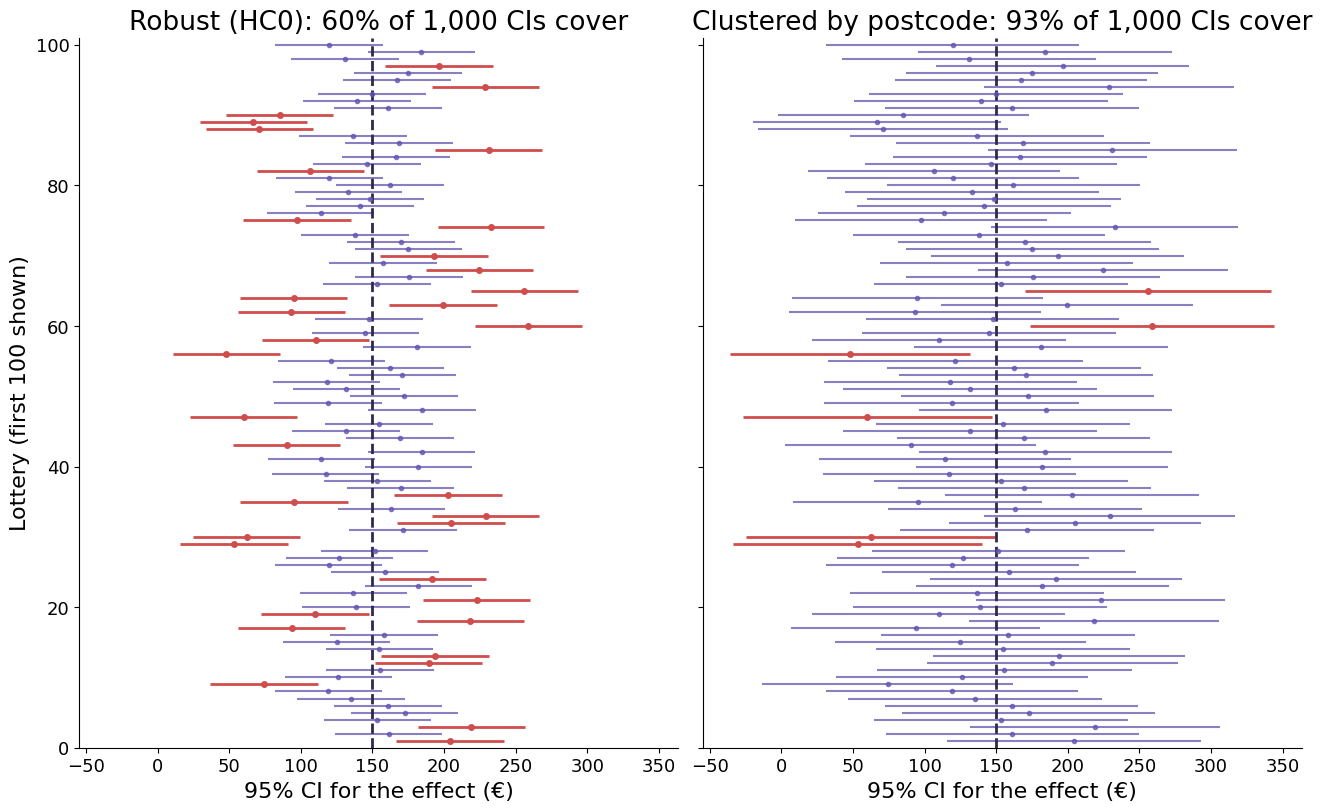

In [15]:
z = stats.norm.ppf(0.975)
fig, axes = plt.subplots(1, 2, figsize=(13, 8), sharex=True, sharey=True)
for ax, se_col, name in [(axes[0], "se_hc0", "Robust (HC0)"), (axes[1], "se_cluster", "Clustered by postcode")]:
    lower = reruns.estimate - z * reruns[se_col]
    upper = reruns.estimate + z * reruns[se_col]
    covers = (lower <= true_effect) & (true_effect <= upper)
    first = reruns.iloc[:100]
    c = covers.iloc[:100].to_numpy()
    y = np.arange(1, 101)
    m = z * first[se_col].to_numpy()
    ax.errorbar(first.estimate[c], y[c], xerr=m[c], fmt="o", ms=3, capsize=0, color="#6554B1", alpha=0.75)
    ax.errorbar(first.estimate[~c], y[~c], xerr=m[~c], fmt="o", ms=4, capsize=0, color="#CF4D4D", lw=2)
    ax.axvline(true_effect, color="#2D2A4A", ls="--", lw=2)
    ax.set(title=f"{name}: {covers.mean():.0%} of 1,000 CIs cover", xlabel="95% CI for the effect (€)")
axes[0].set(ylabel="Lottery (first 100 shown)", ylim=(0, 101))
plt.show()

### How many clusters?

The clustered standard error relies on **many** clusters; in a sense, the number of clusters replaces the sample size. Same design, different numbers of postcodes:

In [16]:
sim_rng = np.random.default_rng(SEED + 5)
rows = []
for n_postcodes in [6, 10, 20, 40, 80]:
    covered = []
    for _ in range(4):  # four different worlds of this size, 250 fair lotteries each
        w = make_world(n_postcodes, sim_rng)
        r = rerun(w, 250, sim_rng)
        covered.append(np.abs(r.estimate - (w.y1 - w.y0).mean()) <= z * r.se_cluster)
    rows.append({"Postcodes": n_postcodes, "Households (approx.)": 19 * n_postcodes,
                 "Clustered 95% CIs that cover the truth": np.mean(np.concatenate(covered))})

display(pd.DataFrame(rows).style.format(
    {"Clustered 95% CIs that cover the truth": "{:.0%}"}).hide(axis="index"))

Postcodes,Households (approx.),Clustered 95% CIs that cover the truth
6,114,83%
10,190,89%
20,380,92%
40,760,95%
80,1520,94%


With only a handful of postcodes, even the clustered intervals cover the truth less than 95% of the time. What matters is how many postcodes were drawn, not how many households live in them.